# Зарплаты в data science, ML и AI: анализ и линейная регрессия на pandas и NumPy

**Задача:** по характеристикам вакансии (опыт, должность, страна и размер компании, удалённость, год) спрогнозировать зарплату в USD и понять, какие факторы с ней связаны.

**Данные:** [Data Science Salaries 2023](https://www.kaggle.com/datasets/arnabchaki/data-science-salaries-2023), автор arnabchaki, первичный источник - ai-jobs.net. Лицензия: Open Data Commons DbCL 1.0.

**Важное уточнение.** Датасет охватывает не весь IT-рынок, а роли в data / ML / AI.

**Инструменты.** Только `pandas`, `numpy` и `matplotlib`. Линейную регрессию, Ridge, разбиение на выборки, кросс-валидацию, метрики и проверку гипотез (перестановочные тесты) мы пишем сами: так видно, что происходит внутри.

**План:** 1) знакомство с данными, 2) качество данных, 3) дубликаты, 4) очистка, 5) выбросы, 6) EDA, 7) корреляции, 8) гипотезы, 9) подготовка к ML, 10) три модели, 11) диагностика, 12) проверки устойчивости, 13) выводы.

In [1]:
import sys

sys.path.append("..")  # чтобы импортировать модули из папки src/

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data_processing import (
    BASELINE, CATEGORICAL_FEATURES, EXPERIENCE_ORDER, NUMERIC_FEATURES, TARGET,
    clean_data, load_raw_data, prepare_train_test, train_test_split_simple,
)
from src.evaluate import metrics_table, plot_diagnostics, regression_metrics
from src.train import ALPHA_GRID, LinearRegressionNP, fit_models

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
FIG = "../reports/figures/"


def savefig(name):
    plt.savefig(FIG + name, dpi=130, bbox_inches="tight")


def boxplot_by(ax, data, col, order, horizontal=False):
    """Рисует boxplot зарплаты для каждой категории столбца col."""
    groups = [data.loc[data[col] == g, TARGET].values for g in order]
    ax.boxplot(groups, vert=not horizontal)
    ticks = range(1, len(order) + 1)
    if horizontal:
        ax.set_yticks(ticks, order)
    else:
        ax.set_xticks(ticks, order)

## 1. Первичное знакомство с данными

Цель: понять, что за таблица перед нами, прежде чем что-либо менять. Исходные данные сохраняем в `df_raw` и дальше не трогаем.

In [2]:
df_raw = load_raw_data("../data/ds_salaries.csv")
print("Размер:", df_raw.shape)
display(df_raw.head())
display(df_raw.tail())

Размер: (3755, 11)


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2023,SE,FT,Principal Data Scientist,80000,EUR,85847,ES,100,ES,L
1,2023,MI,CT,ML Engineer,30000,USD,30000,US,100,US,S
2,2023,MI,CT,ML Engineer,25500,USD,25500,US,100,US,S
3,2023,SE,FT,Data Scientist,175000,USD,175000,CA,100,CA,M
4,2023,SE,FT,Data Scientist,120000,USD,120000,CA,100,CA,M


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
3750,2020,SE,FT,Data Scientist,412000,USD,412000,US,100,US,L
3751,2021,MI,FT,Principal Data Scientist,151000,USD,151000,US,100,US,L
3752,2020,EN,FT,Data Scientist,105000,USD,105000,US,100,US,S
3753,2020,EN,CT,Business Data Analyst,100000,USD,100000,US,100,US,L
3754,2021,SE,FT,Data Science Manager,7000000,INR,94665,IN,50,IN,L


In [3]:
df_raw.info()
print()
print("Пропусков всего:", int(df_raw.isna().sum().sum()))
print()
text_cols = df_raw.select_dtypes(exclude="number").columns
display(df_raw[text_cols].nunique().sort_values().to_frame("уникальных значений"))

<class 'pandas.DataFrame'>
RangeIndex: 3755 entries, 0 to 3754
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   work_year           3755 non-null   int64
 1   experience_level    3755 non-null   str  
 2   employment_type     3755 non-null   str  
 3   job_title           3755 non-null   str  
 4   salary              3755 non-null   int64
 5   salary_currency     3755 non-null   str  
 6   salary_in_usd       3755 non-null   int64
 7   employee_residence  3755 non-null   str  
 8   remote_ratio        3755 non-null   int64
 9   company_location    3755 non-null   str  
 10  company_size        3755 non-null   str  
dtypes: int64(4), str(7)
memory usage: 322.8 KB

Пропусков всего: 0



,уникальных значений
company_size,3
experience_level,4
employment_type,4
salary_currency,20
company_location,72
employee_residence,78
job_title,93


In [4]:
display(df_raw.describe())
for col in ["work_year", "experience_level", "employment_type", "company_size", "remote_ratio"]:
    print(df_raw[col].value_counts().to_dict(), "<-", col)

,work_year,salary,salary_in_usd,remote_ratio
count,"3,755.000","3,755.000","3,755.000","3,755.000"
mean,"2,022.374","190,695.572","137,570.390",46.272
std,0.691,"671,676.501","63,055.625",48.589
min,"2,020.000","6,000.000","5,132.000",0.000
25%,"2,022.000","100,000.000","95,000.000",0.000
50%,"2,022.000","138,000.000","135,000.000",0.000
75%,"2,023.000","180,000.000","175,000.000",100.000
max,"2,023.000","30,400,000.000","450,000.000",100.000


{2023: 1785, 2022: 1664, 2021: 230, 2020: 76} <- work_year
{'SE': 2516, 'MI': 805, 'EN': 320, 'EX': 114} <- experience_level
{'FT': 3718, 'PT': 17, 'CT': 10, 'FL': 10} <- employment_type
{'M': 3153, 'L': 454, 'S': 148} <- company_size
{0: 1923, 100: 1643, 50: 189} <- remote_ratio



**Что видно.**
- 3755 строк и 11 столбцов, пропусков нет, типы корректны. Числовые: `work_year`, `salary`, `salary_in_usd`, `remote_ratio`; остальные семь - категориальные.
- В `job_title` 93 значения, в `employee_residence` 78, в `company_location` 72. Такие признаки нельзя кодировать «в лоб»: нужно объединять редкие категории.
- `salary` содержит разные валюты (максимум 30,4 млн против 450 тыс. у `salary_in_usd`), поэтому `salary` как признак использовать нельзя. Целевая переменная - `salary_in_usd` (от 5 132 до 450 000 USD, медиана 135 000).
- Данные неоднородны: 2022 и 2023 годы дают 92% строк (3449 из 3755), уровень `SE` - 67%, полная занятость `FT` - 99%, компании размера `M` - 84%. Для `PT`, `CT` и `FL` вместе всего 37 строк.

**Решение:** оставляем `salary_in_usd` как цель, `salary` и `salary_currency` исключаем из признаков; редкие категории будем объединять.


## 2. Проверка качества данных

Проверяем то, что может незаметно испортить результат: согласованность двух столбцов зарплаты, курсы конвертации и дублирование между столбцами страны.

In [5]:
usd_rows = df_raw[df_raw["salary_currency"] == "USD"]
print("Строк в USD:", len(usd_rows))
print("salary == salary_in_usd во всех USD-строках:", bool((usd_rows["salary"] == usd_rows["salary_in_usd"]).all()))

non_usd = df_raw[df_raw["salary_currency"] != "USD"].copy()
non_usd["rate"] = non_usd["salary_in_usd"] / non_usd["salary"]
rates = non_usd.groupby(["salary_currency", "work_year"])["rate"].agg(["count", "min", "max"])
rates["разброс курса, %"] = (rates["max"] / rates["min"] - 1) * 100
print("\nСтрок не в USD:", len(non_usd))
print("Максимальный разброс курса внутри пары (валюта, год), %:", round(rates["разброс курса, %"].max(), 4))

same_country = (df_raw["employee_residence"] == df_raw["company_location"]).mean()
print(f"\nДоля строк, где страна сотрудника = стране компании: {same_country:.1%}")

Строк в USD: 3224
salary == salary_in_usd во всех USD-строках: True

Строк не в USD: 531
Максимальный разброс курса внутри пары (валюта, год), %: 0.0158

Доля строк, где страна сотрудника = стране компании: 97.4%



**Что видно.**
- Для 3224 строк в USD `salary` и `salary_in_usd` совпадают полностью.
- Для 531 строки в других валютах курс внутри пары «валюта - год» меняется не более чем на 0,016% (это округление до целого доллара), то есть конвертация выполнена единообразно. Верно ли выбран сам курс, по этим данным проверить нельзя.
- Страна сотрудника совпадает со страной компании в 97,4% строк, поэтому `employee_residence` почти ничего не добавляет к `company_location` и будет исключён.


## 3. Дубликаты

В датасете нет идентификатора вакансии, поэтому по данным нельзя точно отличить повторную запись от нескольких разных людей с одинаковыми характеристиками. Сначала изучим, как устроены повторы.

In [6]:
n_dup = int(df_raw.duplicated().sum())
print(f"Полных дубликатов: {n_dup} из {len(df_raw)} ({n_dup / len(df_raw):.1%})")

tmp = df_raw.copy()
tmp["is_dup"] = tmp.duplicated()               # повтор (кроме первого вхождения)
tmp["has_twin"] = tmp.duplicated(keep=False)   # у строки есть двойник
tmp["round_salary"] = tmp["salary"] % 1000 == 0

print("\nДоля дубликатов по годам:", tmp.groupby("work_year")["is_dup"].mean().round(3).to_dict())
print("По размеру компании:", tmp.groupby("company_size")["is_dup"].mean().round(3).to_dict())
print("По стране (США / не США):", tmp.groupby(tmp["company_location"] == "US")["is_dup"].mean().round(3).to_dict())
print("\nДоля круглых зарплат (кратных 1000) у строк с двойником / без:",
      tmp.groupby("has_twin")["round_salary"].mean().round(3).to_dict())

group_sizes = df_raw.groupby(list(df_raw.columns)).size().sort_values(ascending=False)
print("\nГрупп одинаковых строк (2 и более):", int((group_sizes > 1).sum()))
display(group_sizes.head(5).to_frame("сколько одинаковых строк"))

Полных дубликатов: 1171 из 3755 (31.2%)

Доля дубликатов по годам: {2020: 0.013, 2021: 0.009, 2022: 0.324, 2023: 0.352}
По размеру компании: {'L': 0.099, 'M': 0.357, 'S': 0.007}
По стране (США / не США): {False: 0.084, True: 0.365}

Доля круглых зарплат (кратных 1000) у строк с двойником / без: {False: 0.711, True: 0.687}

Групп одинаковых строк (2 и более): 544


сколько одинаковых строк
work_year experience_level employment_type job_title      salary salary_currency salary_in_usd employee_residence remote_ratio company_location company_size                          
2022      SE               FT              Data Scientist 141525 USD             141525        US                 100          US               M                                   21
                                                          191475 USD             191475        US                 100          US               M                                   21
2023      SE               FT              Data Engineer  252000 USD             252000        US                 0            US               M                                   13
                                                          129000 USD             129000        US                 0            US               M                                   13
2022      SE               FT              Data Scientist 129300 USD             129300        US                 0            US               M                                   12


**Что видно.**
- Полных дубликатов 1171 (31,2%). Они сосредоточены в 2022-2023 годах (32,4% и 35,2% против примерно 1% в 2020-2021), в компаниях размера `M` (35,7% против 0,7% у `S` и 9,9% у `L`) и в США (36,5% против 8,4% в остальных странах).
- Самые большие группы - по 21 одинаковой записи (например, зарплата ровно 141 525 USD).
- Моя первая гипотеза состояла в том, что повторы - это «искусственные» записи с некруглыми суммами. Она **не подтвердилась**: доля круглых зарплат у строк с двойником 68,7%, у остальных 71,1% - разница небольшая.

**Решение.** Удаляем полные дубликаты. Это допущение, а не доказанный факт: без идентификатора вакансии нельзя исключить, что часть повторов - реальные разные люди с одинаковыми характеристиками (столбцы грубые: нет ни компании, ни даты). Но если оставить одинаковые строки, они случайным образом окажутся и в обучающей, и в тестовой выборке, и оценка качества станет не вполне честной. Насколько это влияет на результат, проверяем в разделе 12.


## 4. Очистка

Функция `clean_data` (в `src/data_processing.py`) проверяет отсутствие пропусков и неположительных зарплат, удаляет полные дубликаты и превращает `remote_ratio` в текстовую категорию (0 / 50 / 100 - это режимы работы, а не непрерывная шкала).

In [7]:
df = clean_data(df_raw)
print("До очистки: ", df_raw.shape)
print("После очистки:", df.shape)
print("Удалено строк:", len(df_raw) - len(df))
print("Исходный df_raw не изменён, тип remote_ratio:", df_raw["remote_ratio"].dtype)
display(df["employment_type"].value_counts().to_frame("строк"))
print(df["work_year"].value_counts().sort_index().to_dict(), "<- по годам")
print("Доля вакансий в США:", round((df["company_location"] == "US").mean(), 3))

До очистки:  (3755, 11)
После очистки: (2584, 11)
Удалено строк: 1171
Исходный df_raw не изменён, тип remote_ratio: int64


,строк
employment_type,
FT,2547
PT,17
CT,10
FL,10


{2020: 75, 2021: 228, 2022: 1125, 2023: 1156} <- по годам
Доля вакансий в США: 0.747



**Результат очистки:** 3755 → 2584 строк (удалено 1171 полных дубликата, 31,2%). Пропусков и неположительных зарплат нет, поэтому других строк мы не удаляли. Исходный `df_raw` остался нетронутым.

После очистки в 2022-2023 годах 2281 строка (88%), в США 74,7% вакансий. Тип занятости `FT` - 2547 строк, а `PT`, `CT`, `FL` - 17, 10 и 10: для них статистические выводы невозможны.


## 5. Целевая переменная и выбросы

Смотрим на распределение `salary_in_usd`. Высокие зарплаты автоматически не удаляем: для опытных специалистов они реальны.

Медиана: 130000.0 | асимметрия (skew): 0.62
Границы IQR: [-50,062; 310,038], за границами: 29 (1.1%)


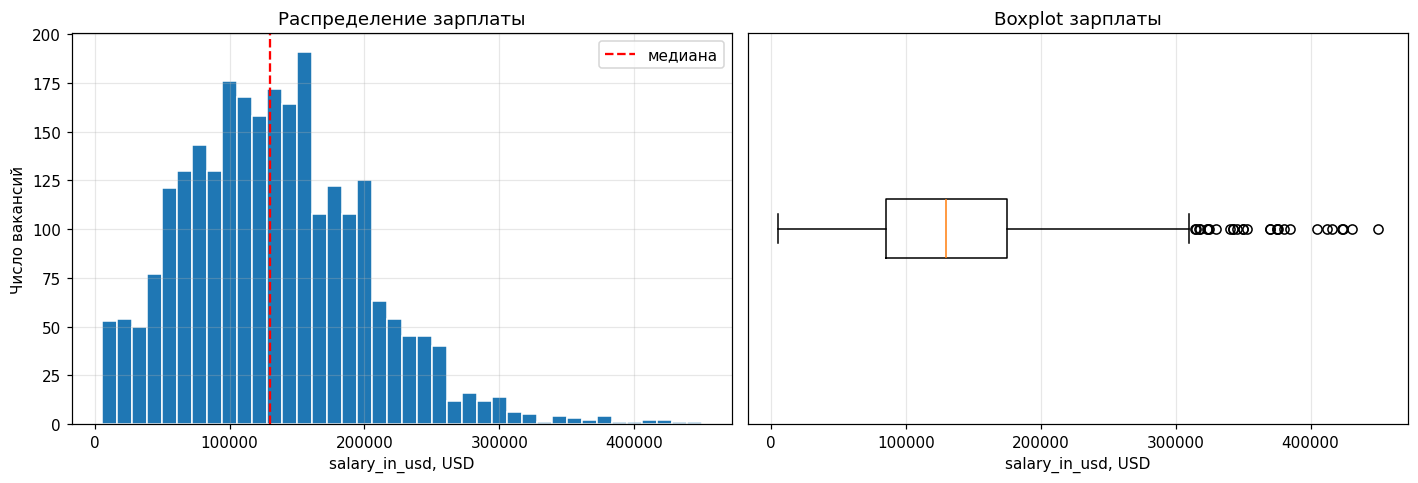


Самые низкие зарплаты:


,work_year,experience_level,job_title,company_location,remote_ratio,salary_in_usd
1759,2022,MI,NLP Engineer,CZ,100,5132
1700,2021,EN,Power BI Developer,IN,50,5409
2368,2021,MI,3D Computer Vision Researcher,IN,50,5409
2497,2021,MI,Data Scientist,US,100,5679
2515,2020,EN,Data Science Consultant,IN,50,5707
1987,2022,MI,Data Analyst,IN,100,5723
2535,2021,EN,Big Data Engineer,CH,0,5882
2423,2020,EN,Data Analyst,IN,0,6072


Самые высокие зарплаты:


,work_year,experience_level,job_title,company_location,remote_ratio,salary_in_usd
2353,2020,MI,Research Scientist,US,0,450000
1352,2022,MI,Data Analyst,GB,0,430967
427,2023,SE,AI Scientist,IL,0,423834
2576,2021,MI,Applied Machine Learning Scientist,US,50,423000
2505,2021,EX,Principal Data Scientist,US,100,416000


Выбросы IQR по уровням опыта:


,выбросов
experience_level,
SE,19
EX,6
MI,4


Медиана зарплаты Data Analyst в Великобритании: 61163.5


In [8]:
y_all = df[TARGET]
print("Медиана:", y_all.median(), "| асимметрия (skew):", round(y_all.skew(), 3))
q1, q3 = y_all.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
mask_out = (y_all < low) | (y_all > high)
print(f"Границы IQR: [{low:,.0f}; {high:,.0f}], за границами: {int(mask_out.sum())} ({mask_out.mean():.1%})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(y_all, bins=40, edgecolor="white")
axes[0].axvline(y_all.median(), color="r", linestyle="--", label="медиана")
axes[0].set(title="Распределение зарплаты", xlabel="salary_in_usd, USD", ylabel="Число вакансий")
axes[0].legend()
axes[1].boxplot(y_all, vert=False)
axes[1].set(title="Boxplot зарплаты", xlabel="salary_in_usd, USD", yticks=[])
plt.tight_layout(); savefig("01_salary_distribution.png"); plt.show()

cols = ["work_year", "experience_level", "job_title", "company_location", "remote_ratio", "salary_in_usd"]
print("\nСамые низкие зарплаты:"); display(df.nsmallest(8, TARGET)[cols])
print("Самые высокие зарплаты:"); display(df.nlargest(5, TARGET)[cols])
print("Выбросы IQR по уровням опыта:"); display(df[mask_out]["experience_level"].value_counts().to_frame("выбросов"))
print("Медиана зарплаты Data Analyst в Великобритании:",
      df[(df["job_title"] == "Data Analyst") & (df["company_location"] == "GB")][TARGET].median())


**Что видно.**
- Асимметрия 0,62: распределение умеренно скошено вправо, длинный «хвост» дорогих позиций. Целевую переменную оставляем в долларах (без логарифма), чтобы MAE и RMSE читались напрямую.
- По правилу IQR выше верхней границы (310 038 USD) лежит 29 наблюдений (1,1%): 19 `SE`, 6 `EX`, 4 `MI`. Нижняя граница отрицательна, поэтому снизу IQR выбросов не находит.
- Самые высокие зарплаты (до 450 000 USD) в основном приходятся на научные и руководящие роли в США и Израиле: правдоподобно. Исключение - строка «Data Analyst, компания в Великобритании, `MI`, 430 967 USD»: у аналитиков в Великобритании медиана около 61 тыс. USD, так что это похоже на ошибку в источнике. Мы её оставили (одна строка из 2584), но влияние на модель отдельно не проверяли.
- Самые низкие (от 5 132 USD): из восьми самых низких пять в Индии, остальные в Чехии, США и Швейцарии; годы 2020-2022, уровни `EN` и `MI`. Для Индии это правдоподобно. Строки «компания в США, 5 679 USD, MI» и «Швейцария, 5 882 USD, EN» вызывают вопросы: возможно, сотрудник жил в другой стране, а возможно, это ошибка (`employee_residence` мы не изучали). Нулей и отрицательных значений нет.

**Ограничение IQR:** метод предполагает примерно симметричное распределение, а у нас зарплата сильно зависит от группы. Для уровня `EX` 300 тыс. USD - обычное значение, а для `EN` - действительно аномалия.

**Решение:** ничего не удаляем: без дополнительной информации нет оснований считать, что значения ошибочны (кроме единичных подозрительных строк, которые отмечены выше).


## 6. Исследовательский анализ (EDA)

Для каждого графика: зачем он нужен, что видно и какие есть ограничения.

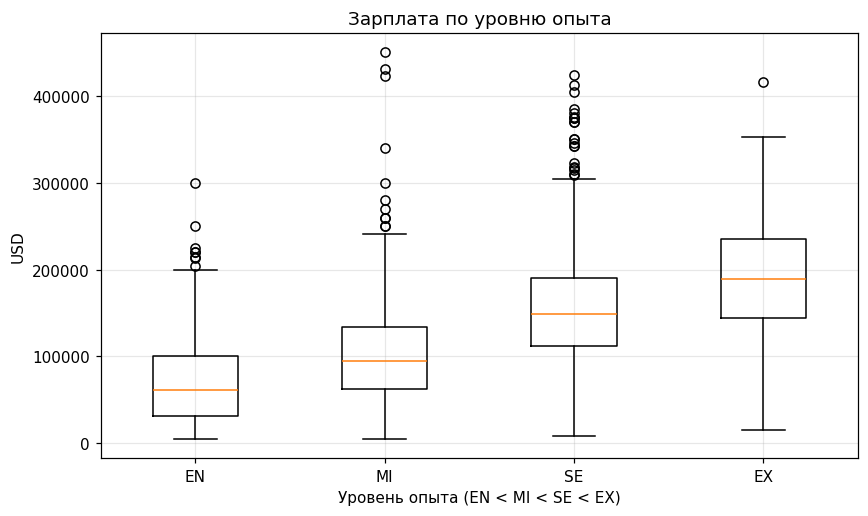

,count,median,mean
experience_level,,,
EN,270,"61,900.000","72,648.685"
MI,664,"95,000.000","101,828.783"
SE,1554,"148,800.000","153,897.436"
EX,96,"189,618.500","191,078.208"


In [9]:
fig, ax = plt.subplots(figsize=(8, 4.8))
boxplot_by(ax, df, "experience_level", EXPERIENCE_ORDER)
ax.set(title="Зарплата по уровню опыта", xlabel="Уровень опыта (EN < MI < SE < EX)", ylabel="USD")
plt.tight_layout(); savefig("02_salary_by_experience.png"); plt.show()
display(df.groupby("experience_level")[TARGET].agg(["count", "median", "mean"]).loc[EXPERIENCE_ORDER])


**Вывод.** Медиана растёт с опытом: `EN` 61 900, `MI` 95 000, `SE` 148 800, `EX` 189 619 USD. Но боксы соседних групп заметно перекрываются: опыт сильно связан с зарплатой, но не определяет её. **Ограничение:** `EX` всего 96 вакансий, а уровень опыта в таких данных обычно указывают сами работодатели или сотрудники, без единого стандарта.


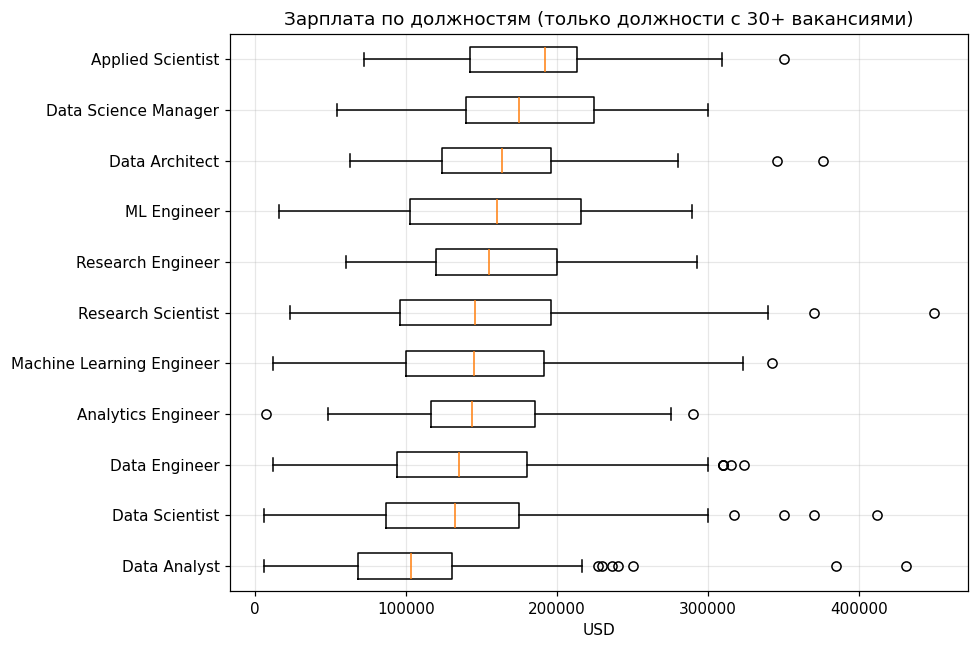

Должностей всего: 93 | покрыто графиком вакансий: 2108 из 2584


,count,median
job_title,,
Data Analyst,396,"102,920.000"
Data Scientist,538,"132,600.000"
Data Engineer,598,"135,000.000"
Analytics Engineer,91,"143,860.000"
Machine Learning Engineer,206,"145,000.000"
Research Scientist,65,"145,900.000"
Research Engineer,33,"155,000.000"
ML Engineer,34,"160,000.000"
Data Architect,64,"163,750.000"


In [10]:
counts = df["job_title"].value_counts()
top_titles = counts[counts >= 30].index
sub = df[df["job_title"].isin(top_titles)]
order = sub.groupby("job_title")[TARGET].median().sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(9, 6))
boxplot_by(ax, sub, "job_title", order, horizontal=True)
ax.set(title="Зарплата по должностям (только должности с 30+ вакансиями)", xlabel="USD")
plt.tight_layout(); savefig("03_salary_by_job_title.png"); plt.show()
print("Должностей всего:", df["job_title"].nunique(), "| покрыто графиком вакансий:", len(sub), "из", len(df))
display(sub.groupby("job_title")[TARGET].agg(["count", "median"]).sort_values("median"))


**Вывод.** Медианы по должностям идут от 102 920 USD (Data Analyst) до 192 000 USD (Applied Scientist). Исследовательские, инженерные и управленческие роли выше аналитических. График показывает 11 должностей, на которые приходится 2108 из 2584 вакансий; остальные 82 должности встречаются реже 30 раз каждая.

**Ограничения.** В группах по 31-65 наблюдений различия между соседними должностями (например, Data Scientist 132 600 и Data Engineer 135 000) нельзя считать надёжными. К тому же должность связана с опытом и страной, поэтому часть различий может быть вызвана составом групп.


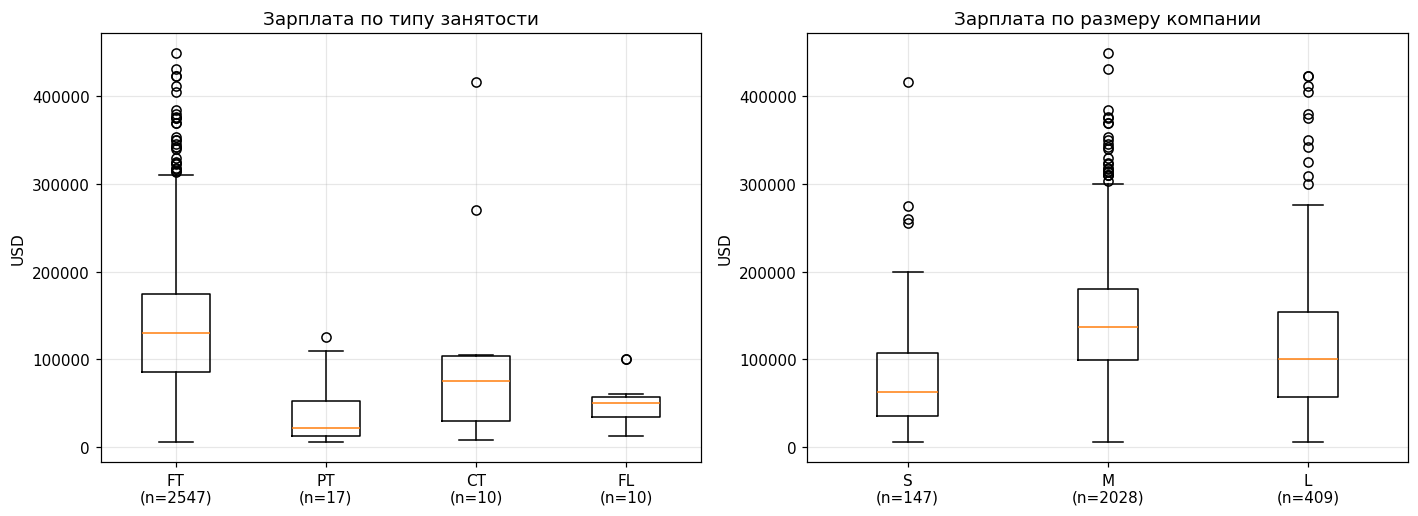

,count,median
employment_type,,
CT,10,"75,000.000"
FL,10,"50,000.000"
FT,2547,"130,000.000"
PT,17,"21,669.000"


,count,median
company_size,,
L,409,"100,000.000"
M,2028,"137,067.500"
S,147,"62,726.000"


Доля вакансий в США по размеру компании: {'L': 0.538, 'M': 0.817, 'S': 0.361}


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
emp_order, size_order = ["FT", "PT", "CT", "FL"], ["S", "M", "L"]
boxplot_by(axes[0], df, "employment_type", emp_order)
n = df["employment_type"].value_counts()
axes[0].set_xticks(range(1, 5), [f"{c}\n(n={n[c]})" for c in emp_order])
axes[0].set(title="Зарплата по типу занятости", ylabel="USD")
boxplot_by(axes[1], df, "company_size", size_order)
n = df["company_size"].value_counts()
axes[1].set_xticks(range(1, 4), [f"{c}\n(n={n[c]})" for c in size_order])
axes[1].set(title="Зарплата по размеру компании", ylabel="USD")
plt.tight_layout(); savefig("04_employment_and_company_size.png"); plt.show()
display(df.groupby("employment_type")[TARGET].agg(["count", "median"]))
display(df.groupby("company_size")[TARGET].agg(["count", "median"]))
print("Доля вакансий в США по размеру компании:",
      df.groupby("company_size")["company_location"].apply(lambda s: (s == "US").mean()).round(3).to_dict())


**Тип занятости.** Медианы: `FT` 130 000, `CT` 75 000, `FL` 50 000, `PT` 21 669 USD, но `PT`, `CT` и `FL` - это 17, 10 и 10 вакансий. Этого достаточно для описания, но не для выводов; поэтому гипотезу о типе занятости мы не проверяем.

**Размер компании.** Медианы: `S` 62 726 (n=147), `M` 137 068 (n=2028), `L` 100 000 (n=409). То, что у крупных компаний медиана **ниже**, чем у средних, неожиданно. Объяснение, которое подтверждается данными: доля вакансий в США - 81,7% у `M`, 53,8% у `L` и 36,1% у `S`. То есть размер компании переплетён со страной, а страна - главный фактор зарплаты. Сырые медианы по размеру нельзя читать как эффект размера (ниже увидим, что при прочих равных `L` получает небольшую надбавку к `M`).


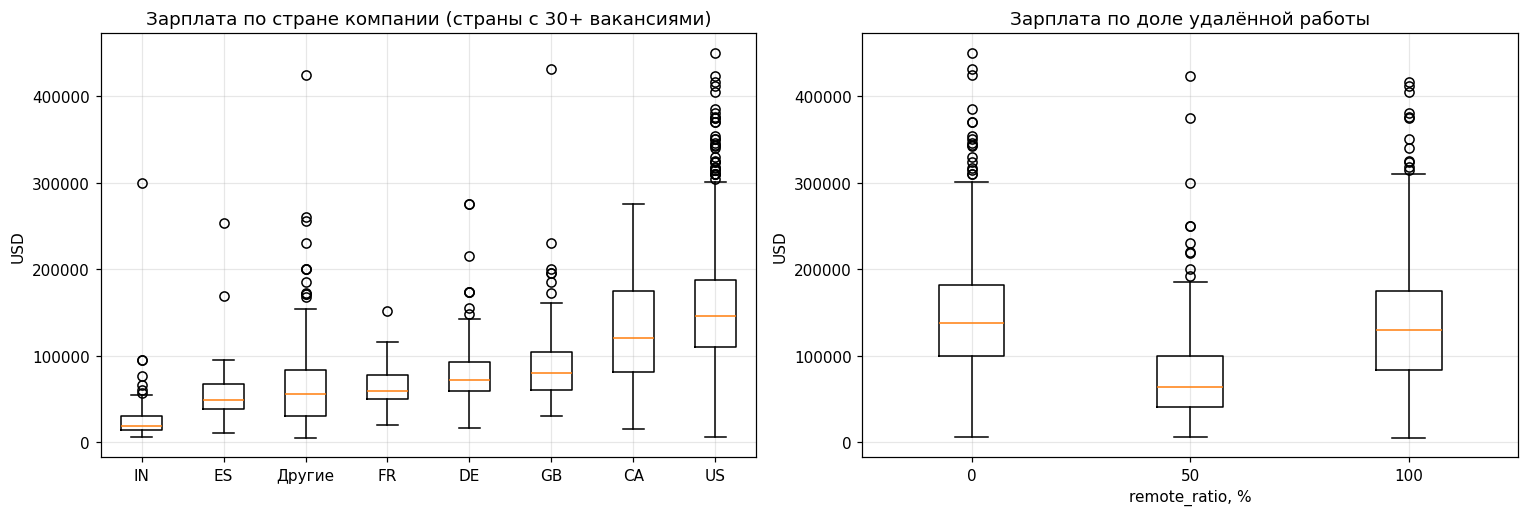

Доля вакансий в США: 0.747


,count,median
loc,,
IN,57,"18,314.000"
ES,44,"48,289.000"
Другие,228,"55,185.000"
FR,33,"59,102.000"
DE,55,"71,897.000"
GB,155,"80,036.000"
CA,83,"120,000.000"
US,1929,"145,885.000"


,count,median
remote_ratio,,
0,1186,"137,500.000"
100,1211,"130,000.000"
50,187,"63,312.000"


Доля вакансий в США по remote_ratio: {'0': 0.82, '100': 0.757, '50': 0.209}


In [12]:
cnt = df["company_location"].value_counts()
frequent = cnt[cnt >= 30].index
loc = df["company_location"].where(df["company_location"].isin(frequent), "Другие")
tmp = df.assign(loc=loc)
order_loc = tmp.groupby("loc")[TARGET].median().sort_values().index.tolist()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
boxplot_by(axes[0], tmp, "loc", order_loc)
axes[0].set(title="Зарплата по стране компании (страны с 30+ вакансиями)", ylabel="USD")
boxplot_by(axes[1], df, "remote_ratio", ["0", "50", "100"])
axes[1].set(title="Зарплата по доле удалённой работы", xlabel="remote_ratio, %", ylabel="USD")
plt.tight_layout(); savefig("05_location_and_remote.png"); plt.show()
print("Доля вакансий в США:", round((df["company_location"] == "US").mean(), 3))
display(tmp.groupby("loc")[TARGET].agg(["count", "median"]).sort_values("median"))
display(df.groupby("remote_ratio")[TARGET].agg(["count", "median"]))
print("Доля вакансий в США по remote_ratio:",
      df.groupby("remote_ratio")["company_location"].apply(lambda s: (s == "US").mean()).round(3).to_dict())


**Страна.** Медианы: США 145 885 USD (1929 вакансий, 74,7% выборки), Канада 120 000, Великобритания 80 036, Германия 71 897, Франция 59 102, Испания 48 289, Индия 18 314. Страны с менее чем 30 вакансиями объединены в «Другие» (медиана 55 185). **Ограничения:** выборка смещена в сторону США, а зарплаты в номинальных долларах без поправки на стоимость жизни.

**Удалённая работа.** Медианы: 0% - 137 500 (n=1186), 100% - 130 000 (n=1211), 50% - 63 312 (n=187). Низкую медиану группы 50% вряд ли стоит объяснять форматом работы: в ней всего 20,9% вакансий в США против 82,0% (офис) и 75,7% (полная удалёнка). Скорее всего, это снова эффект состава.


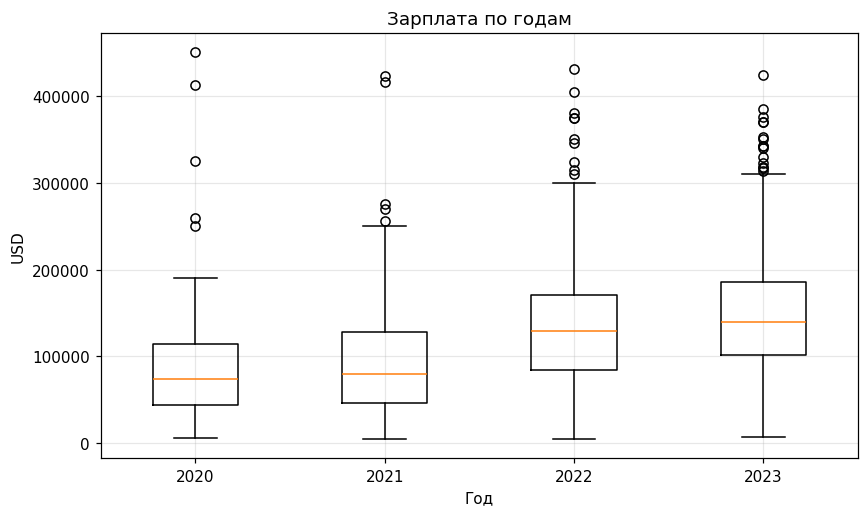

,count,median
work_year,,
2020,75,"74,130.000"
2021,228,"80,000.000"
2022,1125,"129,300.000"
2023,1156,"140,000.000"


,доля США,доля SE и EX
work_year,,
2020,0.413,0.280
2021,0.434,0.364
2022,0.749,0.646
2023,0.827,0.708


In [13]:
fig, ax = plt.subplots(figsize=(8, 4.8))
years = sorted(df["work_year"].unique())
ax.boxplot([df.loc[df["work_year"] == yr, TARGET] for yr in years])
ax.set_xticks(range(1, len(years) + 1), years)
ax.set(title="Зарплата по годам", xlabel="Год", ylabel="USD")
plt.tight_layout(); savefig("06_salary_by_year.png"); plt.show()
display(df.groupby("work_year")[TARGET].agg(["count", "median"]))
share = df.assign(us=df["company_location"] == "US", senior=df["experience_level"].isin(["SE", "EX"]))
display(share.groupby("work_year")[["us", "senior"]].mean().rename(columns={"us": "доля США", "senior": "доля SE и EX"}))


**Что видно.** Медианы по годам: 2020 - 74 130 (n=75), 2021 - 80 000 (n=228), 2022 - 129 300 (n=1125), 2023 - 140 000 (n=1156). Единственный числовой признак принимает всего 4 значения, поэтому вместо диаграммы рассеяния показан boxplot по годам.

**Ограничение интерпретации.** Рост между 2021 и 2022 годами отчасти связан не с зарплатами, а с изменением состава выборки: доля США выросла с 43,4% до 74,9% (2021 → 2022) и 82,7% (2023), доля `SE`+`EX` - с 36,4% до 64,6% и 70,8%. Модель ниже, учитывая страну и опыт, оценивает эффект года в ~5 700 USD в год, то есть гораздо меньше «сырого» роста.


## 7. Корреляционный анализ

**Коэффициент Пирсона** измеряет силу *линейной* связи двух числовых переменных от -1 до +1: знак показывает направление, модуль - силу (около 0 - линейной связи нет, около 1 - почти прямая линия). Он не доказывает причинность и чувствителен к выбросам. Для категорий он не подходит: нельзя считать коды «EN = 0, MI = 1...» числами без обоснования.

В датасете единственный настоящий числовой признак - `work_year` (всего 4 значения). Для категориальных признаков используем другую меру: **долю дисперсии зарплаты, объяснённую группировкой** (η², «эта-квадрат»). Она равна 0, если средние во всех группах одинаковы, и 1, если внутри групп разброса нет.

work_year и salary_in_usd: Пирсон r = 0.237, Спирмен = 0.238, r² = 0.056


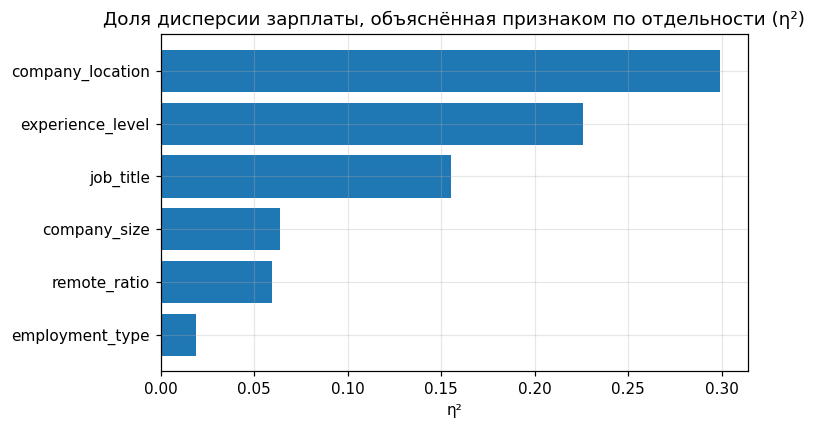

,η²
company_location,0.299
experience_level,0.226
job_title,0.155
company_size,0.064
remote_ratio,0.059
employment_type,0.019


In [14]:
r_pearson = df["work_year"].corr(df[TARGET])
r_spearman = df["work_year"].corr(df[TARGET], method="spearman")
print(f"work_year и salary_in_usd: Пирсон r = {r_pearson:.3f}, Спирмен = {r_spearman:.3f}, r² = {r_pearson ** 2:.3f}")


def eta_squared(frame, cat_col, target=TARGET):
    """Доля дисперсии target, объяснённая группировкой по cat_col (от 0 до 1)."""
    grand_mean = frame[target].mean()
    ss_total = ((frame[target] - grand_mean) ** 2).sum()       # общий разброс
    g = frame.groupby(cat_col)[target]
    ss_between = (g.count() * (g.mean() - grand_mean) ** 2).sum()  # разброс между средними групп
    return ss_between / ss_total


eta = pd.Series({c: eta_squared(df, c) for c in CATEGORICAL_FEATURES}).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(eta.index, eta.values)
ax.set(title="Доля дисперсии зарплаты, объяснённая признаком по отдельности (η²)", xlabel="η²")
plt.tight_layout(); savefig("07_eta_squared.png"); plt.show()
display(eta.round(3).to_frame("η²").sort_values("η²", ascending=False))


**Что видно.**
- `work_year` и зарплата: Пирсон r = 0,237, Спирмен 0,238. Это слабая положительная связь: год объясняет примерно 5,6% дисперсии (r² = 0,056). При 2584 наблюдениях такая связь едва ли случайна, но практически она невелика.
- Для категориальных признаков доля дисперсии зарплаты, объяснённая группировкой (η²): страна компании 0,299, уровень опыта 0,226, должность 0,155, размер компании 0,064, удалёнка 0,059, тип занятости 0,019. Главные «по отдельности» факторы - страна и опыт.

**Ограничения.** Корреляция и η² не доказывают причинность. η² растёт с числом категорий (у `company_location` и `job_title` оно отчасти завышено подгонкой под группы), а признаки связаны между собой (мы видели это на размере компании и годах), поэтому складывать значения η² нельзя.


## 8. Проверка гипотез (перестановочные тесты)

Вместо готовых статистических функций используем **перестановочный тест** - его идею можно объяснить за минуту:

1. Считаем интересующую нас величину на реальных данных (например, разницу медиан двух групп).
2. Допускаем, что H0 верна, то есть метка группы ни на что не влияет. Тогда метки можно случайно перемешать, и разница будет случайной.
3. Перемешиваем метки 10 000 раз и каждый раз считаем ту же величину.
4. **p-value** - доля перемешиваний, в которых величина оказалась не меньше (по модулю) реальной. Если p меньше 0,05, реальная величина слишком необычна для «случайного мира», и H0 отвергаем.

Преимущества: не нужны предположения о нормальности (зарплаты скошены), а метод работает при любых размерах групп. Минимальное p-value ограничено числом перемешиваний: оно не может быть меньше примерно 0,0001.

Как и раньше, различаем статистическую и **практическую значимость**: рядом с p-value считаем размер эффекта. Для двух групп это «вероятность превосходства»: вероятность того, что случайная зарплата из группы A выше случайной зарплаты из группы B (50% - различий нет).

Общее ограничение: перемешивание предполагает независимые наблюдения, а в данных могут быть записи из одной компании или одного отчёта.

In [15]:
N_PERM = 10_000
rng = np.random.default_rng(0)


def perm_test_median_diff(a, b):
    """Перестановочный тест для разницы медиан двух групп. Возвращает (разница, p-value)."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    observed = np.median(a) - np.median(b)
    pooled = np.concatenate([a, b])
    count = 0
    for _ in range(N_PERM):
        shuffled = rng.permutation(pooled)                              # перемешали "метки"
        diff = np.median(shuffled[:len(a)]) - np.median(shuffled[len(a):])
        count += abs(diff) >= abs(observed)
    return observed, (count + 1) / (N_PERM + 1)


def perm_test_eta2(frame, cat_col):
    """Перестановочный тест для η² (несколько групп). Возвращает (η², p-value)."""
    y = frame[TARGET].to_numpy(dtype=float)
    codes, _ = pd.factorize(frame[cat_col])
    n_groups = codes.max() + 1
    ss_total = ((y - y.mean()) ** 2).sum()

    def eta2(labels):
        counts = np.bincount(labels, minlength=n_groups)
        means = np.bincount(labels, weights=y, minlength=n_groups) / counts
        return (counts * (means - y.mean()) ** 2).sum() / ss_total

    observed = eta2(codes)
    count = sum(eta2(rng.permutation(codes)) >= observed for _ in range(N_PERM))
    return observed, (count + 1) / (N_PERM + 1)


def prob_superiority(a, b):
    """Вероятность, что случайное значение из a больше случайного из b (ничьи - пополам)."""
    a, b = np.asarray(a)[:, None], np.asarray(b)[None, :]
    return float((a > b).mean() + 0.5 * (a == b).mean())


# Гипотеза 1: зарплата зависит от уровня опыта
eta2_exp, p1 = perm_test_eta2(df, "experience_level")
print("Гипотеза 1. H0: средние зарплаты одинаковы во всех четырёх группах опыта; H1: хотя бы одна группа отличается.")
print(f"η² = {eta2_exp:.3f}, p-value = {p1:.4f}" + (" (меньше разрешения теста, т.е. p < 0.0001)" if p1 <= 1 / (N_PERM + 1) else ""))
print("Медианы:", df.groupby("experience_level")[TARGET].median().loc[EXPERIENCE_ORDER].to_dict())
print("Решение при α=0.05:", "H0 отвергается" if p1 < 0.05 else "H0 не отвергается")

# Гипотеза 2: удалённая работа (100% против 0%)
a = df.loc[df["remote_ratio"] == "100", TARGET]
b = df.loc[df["remote_ratio"] == "0", TARGET]
diff2, p2 = perm_test_median_diff(a, b)
print("\nГипотеза 2. H0: медианы зарплат при полной удалёнке (100%) и в офисе (0%) одинаковы; H1: различаются.")
print(f"Разница медиан = {diff2:,.0f} USD, p-value = {p2:.4f}, вероятность превосходства = {prob_superiority(a, b):.3f}")
print(f"Медианы: удалёнка 100% = {a.median():,.0f}, офис 0% = {b.median():,.0f}; n = {len(a)} и {len(b)}")
print("Решение при α=0.05:", "H0 отвергается" if p2 < 0.05 else "H0 не отвергается")

# Гипотеза 3: США против остальных стран
us = df.loc[df["company_location"] == "US", TARGET]
non_us = df.loc[df["company_location"] != "US", TARGET]
diff3, p3 = perm_test_median_diff(us, non_us)
print("\nГипотеза 3. H0: медианы зарплат в компаниях США и других стран одинаковы; H1: различаются.")
print(f"Разница медиан = {diff3:,.0f} USD, p-value = {p3:.4f}, вероятность превосходства = {prob_superiority(us, non_us):.3f}")
print(f"Медианы: США = {us.median():,.0f}, остальные = {non_us.median():,.0f}; n = {len(us)} и {len(non_us)}")
print("Решение при α=0.05:", "H0 отвергается" if p3 < 0.05 else "H0 не отвергается")

Гипотеза 1. H0: средние зарплаты одинаковы во всех четырёх группах опыта; H1: хотя бы одна группа отличается.
η² = 0.226, p-value = 0.0001 (меньше разрешения теста, т.е. p < 0.0001)
Медианы: {'EN': 61900.0, 'MI': 95000.0, 'SE': 148800.0, 'EX': 189618.5}
Решение при α=0.05: H0 отвергается



Гипотеза 2. H0: медианы зарплат при полной удалёнке (100%) и в офисе (0%) одинаковы; H1: различаются.
Разница медиан = -7,500 USD, p-value = 0.0160, вероятность превосходства = 0.451
Медианы: удалёнка 100% = 130,000, офис 0% = 137,500; n = 1211 и 1186
Решение при α=0.05: H0 отвергается



Гипотеза 3. H0: медианы зарплат в компаниях США и других стран одинаковы; H1: различаются.
Разница медиан = 80,219 USD, p-value = 0.0001, вероятность превосходства = 0.848
Медианы: США = 145,885, остальные = 65,666; n = 1929 и 655
Решение при α=0.05: H0 отвергается



**Гипотеза 1 (опыт).** H0 отвергается: η² = 0,226, p-value меньше разрешения теста (p < 0,0001). Уровень опыта объясняет около 23% разброса зарплат - по общепринятым ориентирам это крупный эффект. Медианы последовательно растут: 61 900, 95 000, 148 800, 189 619 USD. Тест говорит лишь, что группы в целом различаются; попарные сравнения мы не делали.

**Гипотеза 2 (удалёнка 100% и офис 0%).** H0 отвергается: p ≈ 0,016. Но эффект малый: медианы 130 000 и 137 500 USD (разница 7 500 USD, около 5,5%), вероятность того, что случайная зарплата при полной удалёнке выше случайной «офисной», около 45%. Итог: **статистически значимо, но практически мало**. Из теста нельзя заключить, что удалёнка сама снижает зарплату: страны и должности в группах могут отличаться.

**Гипотеза 3 (США и остальные).** H0 отвергается: p < 0,0001. Медианы 145 885 и 65 666 USD (разница 80 219, в 2,2 раза), вероятность, что случайная зарплата в США выше случайной зарплаты не из США, около 85%. Эффект очень большой. Ограничение: «остальные страны» - неоднородная группа, а зарплаты номинальные.

**Общее ограничение:** перестановочный тест предполагает независимые наблюдения, чего здесь гарантировать нельзя (записи из одной компании, неизвестная природа повторов).


## 9. Подготовка данных к машинному обучению

**Целевая переменная:** `salary_in_usd`.

**Признаки:** `work_year` (число) и категории `experience_level`, `employment_type`, `job_title`, `company_location`, `company_size`, `remote_ratio`.

**Исключены:** `salary` и `salary_currency` (утечка: `salary_in_usd` посчитана из них) и `employee_residence` (почти копия `company_location`).

**Что делает `prepare_train_test`** (функция в `src/data_processing.py`), по шагам:
1. Делит данные на обучающую (80%) и тестовую (20%) части случайно, с фиксированным `seed`.
2. Находит по **обучающей** выборке категории, которые встречаются не реже 30 раз, а остальные превращает в `"Other"`.
3. Кодирует категории столбцами 0/1 (`pd.get_dummies`), пропуская базовую категорию. Например, вместо столбца «страна» появятся `company_location_IN`, `company_location_GB` и т. д.; США (базовая категория) все нули.
4. Масштабирует год: `(год - среднее) / стандартное отклонение`, где среднее и отклонение берутся **только из обучающей части**.
5. Те же правила применяет к тесту.

**Зачем разделять данные.** Тест играет роль «новых данных», которых модель не видела. Если подбирать на нём что-то (категории, масштаб, параметры), оценка качества окажется завышенной, потому что информация из теста «просочилась» в обучение (это называется утечкой данных). Поэтому всё, что чему-то учится на данных, учится только на train.

In [16]:
X_train, X_test, y_train, y_test, scaling = prepare_train_test(df)
print("train:", X_train.shape, "| test:", X_test.shape)
print("Базовые категории:", BASELINE)
print("Столбцы:", list(X_train.columns))
display(X_train.head(3))

train: (2067, 23) | test: (517, 23)
Базовые категории: {'experience_level': 'EN', 'employment_type': 'FT', 'job_title': 'Data Scientist', 'company_location': 'US', 'company_size': 'M', 'remote_ratio': '0'}
Столбцы: ['work_year', 'experience_level_EX', 'experience_level_MI', 'experience_level_SE', 'employment_type_Other', 'job_title_Analytics Engineer', 'job_title_Data Analyst', 'job_title_Data Architect', 'job_title_Data Engineer', 'job_title_Data Science Manager', 'job_title_Machine Learning Engineer', 'job_title_Other', 'job_title_Research Scientist', 'company_location_CA', 'company_location_DE', 'company_location_ES', 'company_location_GB', 'company_location_IN', 'company_location_Other', 'company_size_L', 'company_size_S', 'remote_ratio_100', 'remote_ratio_50']


,work_year,experience_level_EX,experience_level_MI,experience_level_SE,employment_type_Other,job_title_Analytics Engineer,job_title_Data Analyst,job_title_Data Architect,job_title_Data Engineer,job_title_Data Science Manager,job_title_Machine Learning Engineer,job_title_Other,job_title_Research Scientist,company_location_CA,company_location_DE,company_location_ES,company_location_GB,company_location_IN,company_location_Other,company_size_L,company_size_S,remote_ratio_100,remote_ratio_50
2083,-0.401,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000
2134,-0.401,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
957,0.937,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


## 10. Три модели

- **Dummy (медиана)** - ориентир: всегда предсказывает медиану обучающей выборки. Если модель не лучше него, она бесполезна.
- **Линейная регрессия** - ищет такой набор чисел (коэффициентов), при котором сумма квадратов ошибок на обучающих данных минимальна. Прогноз = свободный член + сумма (коэффициент × признак). Свободный член - прогноз для «базового» профиля (все признаки-категории равны 0, год средний), коэффициент у столбца 0/1 - средняя разница в зарплате относительно базовой категории при прочих равных. В коде это одна строка: `np.linalg.lstsq` (решение «нормального уравнения»). Предположения: связь линейная и аддитивная, ошибки независимы и имеют примерно одинаковый разброс, признаки не слишком сильно дублируют друг друга. Реальная зарплата не обязана так устроена (например, надбавка за опыт в США и в Индии разная).
- **Ridge** - та же регрессия с «штрафом» на величину коэффициентов: к сумме квадратов ошибок добавляется alpha × сумма квадратов коэффициентов (L2-регуляризация). Штраф сжимает коэффициенты к нулю, и они меньше «скачут», когда признаки дублируют друг друга (мультиколлинеарность). Но если дублирования и переобучения почти нет, выигрыша может не быть. Параметр alpha выбираем **кросс-валидацией на обучающей выборке**: делим train на 5 частей, по очереди обучаемся на четырёх и проверяем на пятой, берём alpha с минимальной средней ошибкой (MAE).

In [17]:
models, best_alpha, cv_scores = fit_models(X_train, y_train)
print("Подбор alpha для Ridge (кросс-валидация на train), MAE:")
display(pd.Series(cv_scores, name="MAE (CV на train)").rename_axis("alpha").to_frame())
print("Лучший alpha:", best_alpha)

results = metrics_table(models, X_test, y_test)
display(results)
results.to_csv("../reports/metrics.csv")

print("Метрики на обучающей выборке (проверка на переобучение):")
display(metrics_table(models, X_train, y_train))
mae_d, mae_l = results.loc["Dummy (медиана)", "MAE"], results.loc["LinearRegression", "MAE"]
print(f"Улучшение MAE у LinearRegression относительно Dummy: {mae_d - mae_l:,.0f} USD ({1 - mae_l / mae_d:.1%})")
print(f"Медиана зарплаты в тесте: {y_test.median():,.0f} USD; MAE LinearRegression / медиана = {mae_l / y_test.median():.1%}")

Подбор alpha для Ridge (кросс-валидация на train), MAE:


,MAE (CV на train)
alpha,
0.100,"38,412.618"
0.500,"38,411.087"
1.000,"38,417.594"
5.000,"38,543.576"
10.000,"38,775.169"
30.000,"39,840.365"
100.000,"42,051.161"
300.000,"44,687.624"


Лучший alpha: 0.5


,MAE,RMSE,R2
Dummy (медиана),"53,294.677","68,310.076",-0.003
LinearRegression,"38,397.349","53,713.545",0.380
Ridge,"38,384.790","53,705.119",0.380


Метрики на обучающей выборке (проверка на переобучение):


,MAE,RMSE,R2
Dummy (медиана),"52,704.043","66,981.617",-0.004
LinearRegression,"37,863.817","50,301.668",0.434
Ridge,"37,865.735","50,302.703",0.434


Улучшение MAE у LinearRegression относительно Dummy: 14,897 USD (28.0%)
Медиана зарплаты в тесте: 131,752 USD; MAE LinearRegression / медиана = 29.1%



**Что означают метрики.** MAE - средняя абсолютная ошибка прогноза в долларах. RMSE тоже в долларах, но сильнее штрафует крупные ошибки (поэтому он больше MAE). R² - доля дисперсии зарплаты, объяснённая моделью, по сравнению с прогнозом «всегда среднее»; на тесте он может быть отрицательным, если модель хуже такого прогноза (у Dummy он слегка отрицателен: -0,003). Одной метрики недостаточно: MAE показывает типичную ошибку, RMSE - чувствительность к крупным промахам, R² - выигрыш против простого прогноза.

**Результаты на тесте (517 строк).**

| Модель | MAE, USD | RMSE, USD | R² |
|---|---|---|---|
| Dummy (медиана) | 53 295 | 68 310 | -0,003 |
| LinearRegression | 38 397 | 53 714 | 0,380 |
| Ridge (alpha = 0,5) | 38 385 | 53 705 | 0,380 |

- **LinearRegression против Dummy:** MAE ниже на 14 897 USD (28,0%), RMSE ниже на 14 596. Выигрыш реальный. Но типичная ошибка 38 тыс. USD - это ещё 29,1% от медианной зарплаты в тесте (131 752): модель отличает, скажем, начинающего специалиста из Индии от опытного из США, но точную зарплату не предсказывает.
- **Ridge против LinearRegression:** разница в MAE 12 USD (0,03%), R² одинаковый. Кросс-валидация на train почти плоская при alpha от 0,1 до 1 (MAE около 38 411), а при сильном штрафе качество падает (alpha = 300 даёт 44 688): слишком сильное сжатие коэффициентов мешает модели. Суммарный модуль коэффициентов у Ridge меньше всего на 1,0%. Вывод: сильной мультиколлинеарности и переобучения нет, регуляризация не нужна.
- **Переобучение:** на обучающей выборке R² = 0,434 и MAE = 37 864, на тесте 0,380 и 38 397. Разрыв по MAE почти нулевой, по R² умеренный: признаков сильного переобучения нет, модель скорее недообучена (признаков не хватает, см. раздел 11).


Свободный член LinearRegression: 111,194 USD
Коэффициент work_year: 4,245 USD на 1 стандартное отклонение (~5,679 USD за год)
Число признаков: 23

Самые большие положительные коэффициенты (LinearRegression):


,LinearRegression,Ridge
experience_level_EX,"87,513.000","86,681.000"
experience_level_SE,"51,710.000","51,439.000"
job_title_Data Science Manager,"33,125.000","32,755.000"
job_title_Research Scientist,"25,969.000","25,657.000"
job_title_Machine Learning Engineer,"20,685.000","20,533.000"
experience_level_MI,"19,976.000","19,593.000"
job_title_Data Architect,"8,445.000","8,393.000"
job_title_Other,"4,287.000","4,192.000"


Самые большие отрицательные:


,LinearRegression,Ridge
company_location_IN,"-97,388.000","-95,836.000"
company_location_ES,"-78,787.000","-77,674.000"
company_location_Other,"-66,840.000","-66,433.000"
company_location_GB,"-50,543.000","-50,135.000"
company_location_DE,"-42,211.000","-41,563.000"
job_title_Data Analyst,"-30,113.000","-30,149.000"
company_location_CA,"-17,091.000","-16,767.000"
employment_type_Other,"-12,282.000","-12,157.000"


Сумма |коэффициентов|: LinearRegression = 676296 | Ridge = 669627


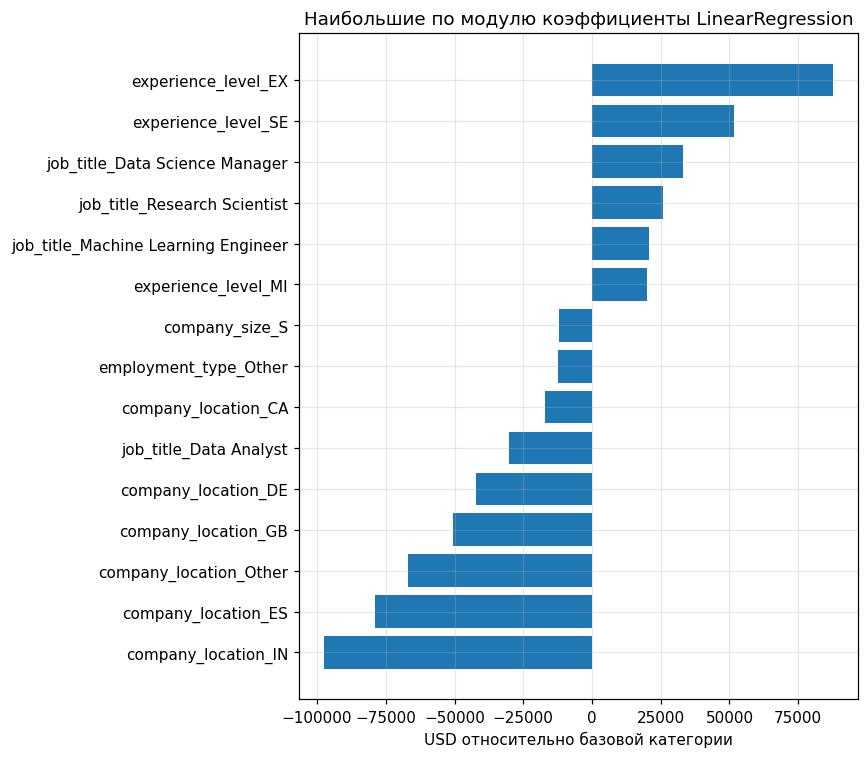

In [18]:
names = list(X_train.columns)
coefs = pd.DataFrame({"LinearRegression": models["LinearRegression"].coef_,
                      "Ridge": models["Ridge"].coef_}, index=names)
print(f"Свободный член LinearRegression: {models['LinearRegression'].intercept_:,.0f} USD")
wy = coefs.loc["work_year", "LinearRegression"]
print(f"Коэффициент work_year: {wy:,.0f} USD на 1 стандартное отклонение (~{wy / scaling['std']['work_year']:,.0f} USD за год)")
print(f"Число признаков: {len(names)}")

print("\nСамые большие положительные коэффициенты (LinearRegression):")
display(coefs.sort_values("LinearRegression", ascending=False).head(8).round(0))
print("Самые большие отрицательные:")
display(coefs.sort_values("LinearRegression").head(8).round(0))
print("Сумма |коэффициентов|: LinearRegression =", round(coefs["LinearRegression"].abs().sum()),
      "| Ridge =", round(coefs["Ridge"].abs().sum()))

top = coefs["LinearRegression"].reindex(coefs["LinearRegression"].abs().sort_values(ascending=False).head(15).index).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top.index, top.values)
ax.set(title="Наибольшие по модулю коэффициенты LinearRegression", xlabel="USD относительно базовой категории")
plt.tight_layout(); savefig("08_coefficients.png"); plt.show()


**Как читать коэффициенты.** Категории закодированы столбцами 0/1 относительно базовой категории: `EN`, `FT`, `Data Scientist`, `US`, компания `M`, удалёнка 0%. Свободный член (111 194 USD) - прогноз для такого базового профиля со средним годом. Коэффициент показывает среднюю разницу в зарплате относительно базовой категории **при прочих равных в этой выборке** (это не причинный эффект).

- **Опыт** (относительно `EN`): `EX` +87 513, `SE` +51 710, `MI` +19 976 USD.
- **Страна** (относительно США): Индия -97 388, Испания -78 787, Великобритания -50 543, Германия -42 211, Канада -17 091 USD; редкие страны вместе -66 840.
- **Должность** (относительно Data Scientist): Data Science Manager +33 125, Research Scientist +25 969, Machine Learning Engineer +20 685, Data Analyst -30 113 USD.
- **Размер компании** (относительно `M`): `L` +2 015, `S` -11 912 USD. У `L` сырая медиана была ниже, чем у `M`, а при прочих равных выше: это эффект состава (в `L` 46% вакансий вне США против 18% в `M`), хотя сама надбавка небольшая.
- **Удалёнка** (относительно офиса): 100% удалёнка -1 817, 50% -3 772 USD: при учёте страны и опыта разница небольшая.
- **Год:** около +5 700 USD в год (4 245 USD на одно стандартное отклонение года).

**Оговорки.** Категория `Other` объединяет разнородные должности и страны и самостоятельно не интерпретируется. Значимость коэффициентов мы не оценивали. Коэффициенты Ridge почти совпадают с обычными.


## 11. Диагностика лучшей модели

Лучшей считаем модель с наименьшей MAE на тесте (метрику выбрали заранее: она измеряется в долларах и меньше зависит от редких крупных промахов, чем RMSE).

Лучшая модель по MAE: Ridge


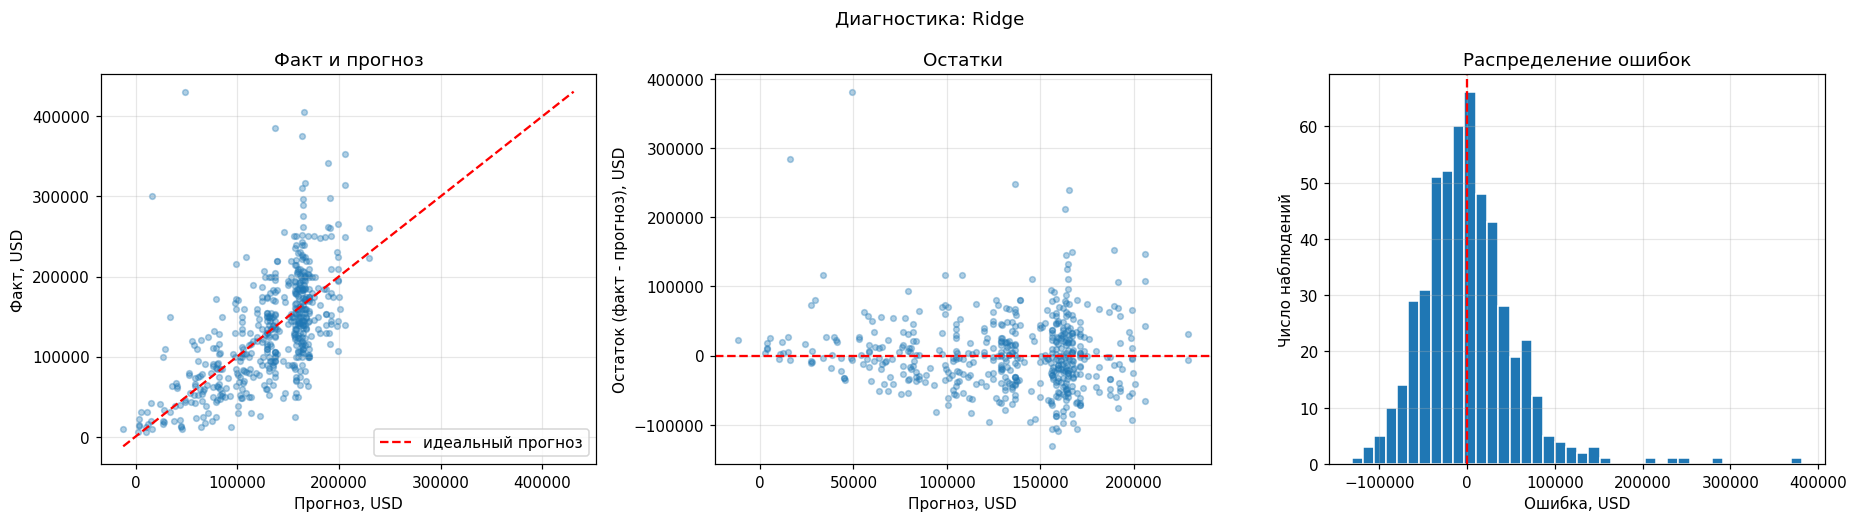

Средняя ошибка (факт - прогноз) по квартилям фактической зарплаты:


,count,mean
salary_quartile,,
Q1 (низкие),131,"-31,308.218"
Q2,128,"-20,585.578"
Q3,133,946.396
Q4 (высокие),125,"60,198.421"


MAE по уровням опыта:


,MAE
exp,
EN,"37,876.285"
MI,"32,205.879"
SE,"40,259.446"
EX,"54,325.564"


Доля прогнозов ниже нуля: 0.002 | минимальный прогноз: -12127


In [19]:
best_name = results["MAE"].idxmin()
best_model = models[best_name]
pred = best_model.predict(X_test)
print("Лучшая модель по MAE:", best_name)
plot_diagnostics(y_test, pred, title=f"Диагностика: {best_name}", save_path=FIG + "09_diagnostics.png")
plt.show()

res = pd.DataFrame({"y": y_test.values, "pred": pred})
res["error"] = res["y"] - res["pred"]
res["exp"] = df.loc[y_test.index, "experience_level"].values
res["salary_quartile"] = pd.qcut(res["y"], 4, labels=["Q1 (низкие)", "Q2", "Q3", "Q4 (высокие)"])
print("Средняя ошибка (факт - прогноз) по квартилям фактической зарплаты:")
display(res.groupby("salary_quartile", observed=True)["error"].agg(["count", "mean"]))
print("MAE по уровням опыта:")
display(res.groupby("exp")["error"].apply(lambda s: s.abs().mean()).loc[EXPERIENCE_ORDER].to_frame("MAE"))
print("Доля прогнозов ниже нуля:", round(float((pred < 0).mean()), 3), "| минимальный прогноз:", round(float(pred.min())))

In [20]:
# Чувствительность к одному самому большому промаху (не для подгонки модели, а чтобы оценить его вес)
i_max = int(np.argmax(np.abs(res["error"].values)))
print("Самый большой промах:", df.loc[y_test.index[i_max], ["job_title", "company_location", "experience_level"]].to_dict(),
      "| факт", round(float(res.loc[i_max, "y"])), "| прогноз", round(float(res.loc[i_max, "pred"])))
keep = np.arange(len(res)) != i_max
print("Метрики без этой строки:", {k: round(v, 3) for k, v in regression_metrics(y_test.values[keep], pred[keep]).items()})
print("Метрики со всеми строками:", {k: round(v, 3) for k, v in regression_metrics(y_test, pred).items()})
print("Максимальный прогноз:", round(float(pred.max())), "| максимальная фактическая зарплата в тесте:", int(y_test.max()))

Самый большой промах: {'job_title': 'Data Analyst', 'company_location': 'GB', 'experience_level': 'MI'} | факт 430967 | прогноз 49065
Метрики без этой строки: {'MAE': 37719.059, 'RMSE': 51060.514, 'R2': 0.419}
Метрики со всеми строками: {'MAE': 38384.79, 'RMSE': 53705.119, 'R2': 0.38}
Максимальный прогноз: 229191 | максимальная фактическая зарплата в тесте: 430967



**Что показывают графики и таблицы.** Лучшей по MAE оказалась Ridge, но её отличие от LinearRegression (12 USD) не имеет практического смысла: диагностика относится к обеим моделям.
- **Факт и прогноз:** точки широко рассеяны вокруг диагонали. Максимальный прогноз около 229 тыс. USD, а фактические зарплаты в тесте доходят до 431 тыс.: модель не предсказывает очень высокие значения.
- **Систематическая ошибка:** в нижних квартилях фактической зарплаты прогноз в среднем завышен (на 31 308 USD в Q1 и 20 586 в Q2), в верхнем - занижен (на 60 198 в Q4). Часть этого эффекта возникает механически из-за деления по фактическому значению, но величина паттерна говорит и о нехватке признаков.
- **Ошибка по опыту:** MAE у `EN` 37 876, `MI` 32 206, `SE` 40 259, `EX` 54 326 USD. Она максимальна у руководящего уровня (`EX`), где зарплаты выше и разброс больше: это нарушает предположение линейной регрессии о постоянном разбросе ошибок.
- **Отрицательные прогнозы:** 0,2% (минимум -12 127 USD): линейная модель не «знает», что зарплата не может быть меньше нуля.
- **Один сильный промах:** самая большая ошибка приходится на ту самую строку «Data Analyst, Великобритания, `MI`, 430 967 USD», которая выглядела подозрительно ещё в разделе 5 (прогноз около 49 тыс.). Без неё метрики теста были бы лучше: MAE 37 719, RMSE 51 061, R² 0,419 вместо 38 385, 53 705 и 0,380. Строку мы **не удаляем** (решение принято до обучения), но видно, как одна возможная ошибка в данных двигает RMSE и R².

**Что это значит.** Линейная аддитивная модель не улавливает взаимодействия (например, надбавка за опыт в США и в Индии разная) и не видит факторов, которых нет в данных: навыков, компании, города, бонусов. Улучшения (логарифм цели, взаимодействия, деревья) выходят за рамки проекта.


## 12. Проверки устойчивости

**а) Разные разбиения.** Результат одного разбиения 80/20 может быть случайностью, поэтому повторяем всю процедуру (включая подбор `alpha` внутри обучающей части) на 10 разных разбиениях.

**б) Дубликаты.** Что было бы, если бы мы не удаляли дубликаты? При случайном разбиении одинаковые строки попадают и в train, и в test, и модель получает «подсказку».

In [21]:
rows = []
for seed in range(10):
    Xtr, Xte, ytr, yte, _ = prepare_train_test(df, seed=seed)
    ms, _, _ = fit_models(Xtr, ytr)
    for name, m in ms.items():
        rows.append({"seed": seed, "model": name, **regression_metrics(yte, m.predict(Xte))})
rep = pd.DataFrame(rows)
display(rep.groupby("model")[["MAE", "RMSE", "R2"]].agg(["mean", "std"]).round(3))
mae_by_seed = rep.pivot(index="seed", columns="model", values="MAE")
print("Ridge лучше LinearRegression по MAE в", int((mae_by_seed["Ridge"] < mae_by_seed["LinearRegression"]).sum()), "из 10 разбиений")

MAE                 RMSE               R2      
                       mean       std       mean       std   mean   std
model                                                                  
Dummy (медиана)  53,309.481 1,665.452 68,738.402 2,558.153 -0.014 0.015
LinearRegression 39,318.265 1,282.040 53,748.830 2,939.457  0.380 0.039
Ridge            39,320.825 1,285.115 53,748.379 2,938.557  0.380 0.039

Ridge лучше LinearRegression по MAE в 6 из 10 разбиений


In [22]:
# б) модель на данных С дубликатами (тот же случайный разбиватель)
df_dups = df_raw.copy()
df_dups["remote_ratio"] = df_dups["remote_ratio"].astype(str)
Xd_tr, Xd_te, yd_tr, yd_te, _ = prepare_train_test(df_dups)
models_d, _, _ = fit_models(Xd_tr, yd_tr)
print(f"С дубликатами: {len(df_dups)} строк; без дубликатов: {len(df)} строк\n")
display(metrics_table(models_d, Xd_te, yd_te))


def twin_share(frame):
    """Доля тестовых строк, у которых в train есть точная копия (по признакам и зарплате)."""
    full = frame[NUMERIC_FEATURES + CATEGORICAL_FEATURES].assign(salary=frame[TARGET].values)
    tr, te, _, _ = train_test_split_simple(full, full["salary"])
    merged = te.merge(tr.drop_duplicates(), how="left", indicator=True)
    return float((merged["_merge"] == "both").mean())


print("Доля тестовых строк с точным двойником в train (с дубликатами):", round(twin_share(df_dups), 3))
print("Доля тестовых строк с точным двойником в train (без дубликатов):", round(twin_share(df), 3))

# Один результат может быть случайным, поэтому повторяем сравнение на 10 разбиениях (только LinearRegression)
rows = []
for seed in range(10):
    for label, frame in [("с дубликатами", df_dups), ("без дубликатов", df)]:
        Xa, Xb, ya, yb, _ = prepare_train_test(frame, seed=seed)
        pred_b = LinearRegressionNP().fit(Xa, ya).predict(Xb)
        rows.append({"данные": label, **regression_metrics(yb, pred_b)})
print("\nLinearRegression на 10 разбиениях:")
display(pd.DataFrame(rows).groupby("данные")[["MAE", "RMSE", "R2"]].agg(["mean", "std"]).round(3))

С дубликатами: 3755 строк; без дубликатов: 2584 строк



,MAE,RMSE,R2
Dummy (медиана),"50,363.820","62,556.541",-0.001
LinearRegression,"35,395.145","45,834.770",0.463
Ridge,"35,396.506","45,834.116",0.463


Доля тестовых строк с точным двойником в train (с дубликатами): 0.378
Доля тестовых строк с точным двойником в train (без дубликатов): 0.0



LinearRegression на 10 разбиениях:


MAE                 RMSE              R2      
                     mean       std       mean       std  mean   std
данные                                                              
без дубликатов 39,318.265 1,282.040 53,748.830 2,939.457 0.380 0.039
с дубликатами  36,370.592 1,018.743 47,703.870 1,840.171 0.406 0.025


**а) Разные разбиения.** Среднее по 10 разбиениям: Dummy MAE 53 309 ± 1 665; LinearRegression MAE 39 318 ± 1 282, R² 0,380 ± 0,039; Ridge MAE 39 321 ± 1 285, R² 0,380 ± 0,039. Ridge лучше в 6 из 10 разбиений, но в среднем разница в пару долларов, то есть модели неразличимы. Разброс R² между разбиениями (±0,04) заметен: корректнее говорить «R² около 0,38 ± 0,04», чем опираться на одно число.

**б) Дубликаты.** На данных с дубликатами (3755 строк) на разбиении, которое мы использовали выше, LinearRegression показывает R² = 0,463 и MAE = 35 395 против 0,380 и 38 397 без дубликатов; при этом 37,8% тестовых строк имели в обучающей выборке точного двойника (после очистки - 0%). Одно разбиение может быть нетипичным, поэтому сравнение повторено на 10 разбиениях: с дубликатами R² = 0,406 ± 0,025 и MAE = 36 371 ± 1 019, без дубликатов R² = 0,380 ± 0,039 и MAE = 39 318 ± 1 282. Тестовые выборки в двух вариантах разные, поэтому сравнение приблизительное, но в среднем дубликаты делают оценку качества оптимистичнее (R² выше на ~0,03, MAE ниже на ~3 тыс. USD). Это аргумент в пользу решения их удалить.



## 13. Выводы и ограничения

**Выводы.**
1. Сильнее всего с зарплатой связаны страна компании (η² = 0,30) и уровень опыта (0,23), затем должность (0,16). Размер компании и формат работы связаны слабее. Из трёх гипотез две дали большой эффект (опыт, США против остальных), одна - статистически значимый, но малый (удалёнка).
2. LinearRegression снижает MAE на 28% по сравнению с прогнозом медианой (38 397 против 53 295 USD) и объясняет около 38% дисперсии на тесте (0,380 ± 0,039 по 10 разбиениям). Типичная ошибка - около 38 тыс. USD, примерно 29% от медианной зарплаты.
3. Ridge качества не улучшил: сильной мультиколлинеарности и переобучения в данных нет.
4. Модель завышает прогноз для низких зарплат и занижает для высоких; ошибки максимальны на уровне `EX`.

**Ограничения.**
- Данные только по ролям data / ML / AI; 75% вакансий в США, 88% наблюдений относятся к 2022-2023 годам. Вывод нельзя переносить на весь IT-рынок.
- Решение удалить 1171 дубликат принято без идентификатора вакансии и является допущением; проверка показывает, что оставленные дубликаты делают оценку качества несколько оптимистичнее.
- В данных нет навыков, названия компании, города, образования, бонусов; зарплата номинальная, без поправки на стоимость жизни.
- Корреляции и коэффициенты не доказывают причинность; признаки связаны между собой (страна, размер, год, опыт).
- Модель линейная и аддитивная, взаимодействия не учитываются; есть отрицательные прогнозы.
- Перестановочные тесты предполагают независимость наблюдений, которую здесь гарантировать нельзя.
- В данных есть единичные подозрительные строки (например, аналитик в Великобритании с 430 967 USD). Одна такая строка заметно двигает RMSE и R² на тесте (раздел 11), но решение их не удалять принято до обучения моделей.
- Категории реже 30 наблюдений объединены в `Other`, поэтому для них модель не даёт конкретных оценок.
